# P10: where does the ResNet go wrong, and why?

The ResNet scores about 80 to 86%. Which genres does it mix up, and what does that tell us? We take one saved model and look at its
**predictions on the validation images** (480 images, 96 per genre), not only at its accuracy:

1. **The confusion matrix** and the precision and recall of each genre.
2. **The most frequent mistakes**, and whether the two genres of a pair "look alike" to the network (how close their average
   features are).
3. **How sure the model is** when it is right and when it is wrong, and whether the true genre is at least its second choice.
4. **The link with style and artist** (the metadata we never gave to the model): are some styles harder?
5. **The most confident mistakes**, which are the best candidates for ambiguous labels (a religious painting that is also a portrait).

Change `RUN` below to analyse another saved run. **Only validation is used here, not the test set** (ADR 0003): looking at test errors to
improve the model would turn museum B into a tuning set.

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from deep_learning_project_waerniers_lamy.vision.utils import (
    DATA_DIR, RESULTS_DIR, build_resnet_head, load_resnet_data, load_result, summary)

# Which saved run to analyse: "resnet18_head" (frozen), "resnet18_layer4" (last block trained), "resnet18_layer4_3seeds",
# "resnet50_head"... For a run repeated over several seeds, the saved weights are those of the first seed.
RUN = "resnet18_layer4"

runs_table = summary()
stem = runs_table[runs_table["name"] == RUN].sort_values("date")["file"].iloc[0]
saved = load_result(stem)
config = saved["config"]
print("analysing:", stem)
print({k: v for k, v in config.items() if k in ("model", "image_size", "finetune", "features", "augment")})

analysing: resnet18_layer4_2026-10-22_17-21-37
{'model': 'resnet18', 'image_size': 224, 'finetune': 'layer4'}


## 1. The predictions

We rebuild the model from its config, load its saved weights, and predict the validation images. A check makes sure we get back the
accuracy that was saved with the run.

In [3]:
data = load_resnet_data(config, splits=("val",))  # the validation images, passed through the frozen part (about 15 s)
classes = data["classes"]
y = data["y_val"]

model = build_resnet_head(config)
model.load_state_dict(torch.load(RESULTS_DIR / f"{stem}.pt"))
model.eval()
with torch.no_grad():
    probs = model(data["X_val"]).softmax(dim=1)  # one probability per genre and per image
predicted = probs.argmax(dim=1)

accuracy = (predicted == y).float().mean().item()
print(f"validation accuracy: {accuracy:.1%} (saved with the run: {saved['best_val_acc']:.1%})")
assert abs(accuracy - saved["best_val_acc"]) < 1e-6, "the predictions do not match the saved run"

# The table of the validation images (same order as the predictions), with the metadata the model never saw.
split_table = pd.read_csv(DATA_DIR / "split.csv")
val = split_table[split_table["split"] == "val"].reset_index(drop=True)
val = val.merge(pd.read_csv(DATA_DIR / "metadata.csv")[["id", "style"]], on="id", how="left")
val["predicted"] = [classes[i] for i in predicted]
val["confidence"] = probs.max(dim=1).values.numpy()
val["correct"] = (predicted == y).numpy()

validation accuracy: 83.3% (saved with the run: 83.3%)


## 2. The confusion matrix

Rows are the true genre, columns the predicted genre. In the picture, each row is shown as a percentage of the true genre, so the
diagonal is the recall of each genre.

predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,73,18,0,3,2
landscape,6,84,0,2,4
portrait,0,0,76,7,13
religious_painting,3,3,13,76,1
still_life,0,1,3,1,91


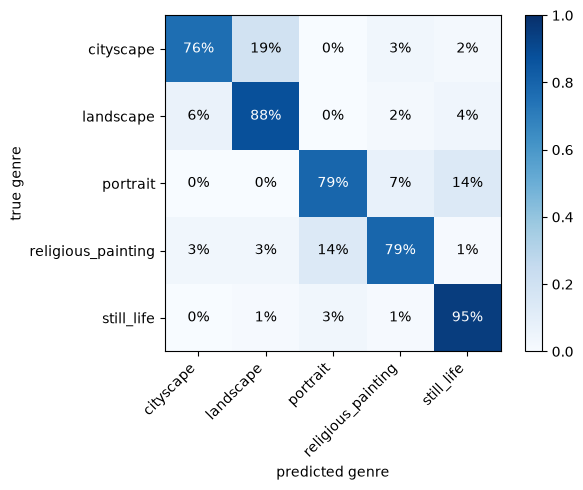

In [4]:
confusion = pd.crosstab(pd.Series([classes[i] for i in y], name="true genre"), pd.Series(val["predicted"], name="predicted"))
confusion = confusion.reindex(index=classes, columns=classes, fill_value=0)
display(confusion)

shares = confusion.div(confusion.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(shares.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)))
ax.set_yticklabels(classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{100 * shares.values[i, j]:.0f}%", ha="center", va="center",
                color="white" if shares.values[i, j] > 0.5 else "black")
ax.set_xlabel("predicted genre")
ax.set_ylabel("true genre")
plt.colorbar(image)
plt.tight_layout()
plt.show()

In [5]:
true_positives = np.diag(confusion.values)
recall = true_positives / confusion.sum(axis=1).values  # of the images of this genre, the share found
precision = true_positives / confusion.sum(axis=0).values  # of the images called this genre, the share that really are
pd.DataFrame({"recall (%)": 100 * recall, "precision (%)": 100 * precision,
              "F1 (%)": 100 * 2 * precision * recall / (precision + recall)}, index=classes).round(1)

,recall (%),precision (%),F1 (%)
cityscape,76.0,89.0,82.0
landscape,87.5,79.2,83.2
portrait,79.2,82.6,80.9
religious_painting,79.2,85.4,82.2
still_life,94.8,82.0,87.9


## 3. The most frequent mistakes

Every "true genre predicted as another genre", from the most to the least frequent.

In [6]:
pairs = pd.DataFrame([
    {"true genre": classes[i], "predicted as": classes[j], "images": confusion.iloc[i, j],
     "% of the true genre": 100 * confusion.iloc[i, j] / confusion.iloc[i].sum()}
    for i in range(len(classes)) for j in range(len(classes)) if i != j
]).sort_values("images", ascending=False)
pairs.head(8).round(1)

,true genre,predicted as,images,% of the true genre
0,cityscape,landscape,18,18.8
11,portrait,still_life,13,13.5
14,religious_painting,portrait,13,13.5
10,portrait,religious_painting,7,7.3
4,landscape,cityscape,6,6.2
7,landscape,still_life,4,4.2
2,cityscape,religious_painting,3,3.1
18,still_life,portrait,3,3.1


### Do the mixed-up genres "look alike" to the network?

We measure how close two genres are in the network's own feature space: the average feature vector of each genre (the 512 numbers it
computes just before its answer), and the cosine similarity between these averages (1 means the same direction). If the intuition
"religious paintings and portraits look alike" holds, the pairs with the highest similarity should be the ones with the most mistakes
in both directions.

In [7]:
with torch.no_grad():
    if config.get("finetune", "head") == "layer4":
        embeddings = model[:3](data["X_val"])  # the trained last block, pooled: 512 numbers per image
    else:
        embeddings = data["X_val"]  # the frozen features: already one vector per image
centroids = torch.stack([embeddings[y == k].mean(dim=0) for k in range(len(classes))])
centroids = centroids / centroids.norm(dim=1, keepdim=True)
similarity = pd.DataFrame((centroids @ centroids.T).numpy(), index=classes, columns=classes)

pair_rows = []
for i in range(len(classes)):
    for j in range(i + 1, len(classes)):
        pair_rows.append({"genre A": classes[i], "genre B": classes[j], "similarity of the averages": similarity.iloc[i, j],
                          "mistakes A to B": confusion.iloc[i, j], "mistakes B to A": confusion.iloc[j, i],
                          "mistakes, both ways": confusion.iloc[i, j] + confusion.iloc[j, i]})
pair_table = pd.DataFrame(pair_rows).sort_values("similarity of the averages", ascending=False)
display(pair_table.round(3))
similarity_rank = pair_table["similarity of the averages"].rank()
mistakes_rank = pair_table["mistakes, both ways"].rank()
print(f"rank correlation between similarity and mistakes (10 pairs): {similarity_rank.corr(mistakes_rank):.2f}")

,genre A,genre B,similarity of the averages,mistakes A to B,mistakes B to A,"mistakes, both ways"
0,cityscape,landscape,0.882,18,6,24
7,portrait,religious_painting,0.865,7,13,20
8,portrait,still_life,0.795,13,3,16
9,religious_painting,still_life,0.722,1,1,2
6,landscape,still_life,0.700,4,1,5
2,cityscape,religious_painting,0.675,3,3,6
3,cityscape,still_life,0.675,2,0,2
5,landscape,religious_painting,0.674,2,3,5
4,landscape,portrait,0.647,0,0,0
1,cityscape,portrait,0.633,0,0,0


rank correlation between similarity and mistakes (10 pairs): 0.86


## 4. How sure is the model?

If the model is unsure when it is wrong, the mistakes are "reasonable doubts". If it is sure, the label or the picture is probably
ambiguous. We also look at the **second choice**: how often is the true genre at least the second most probable one?

mean confidence when right: 0.90 | when wrong: 0.71
mistakes made with a confidence above 0.8: 29 of 80
top-1 accuracy 83.3% | top-2 accuracy 95.4%


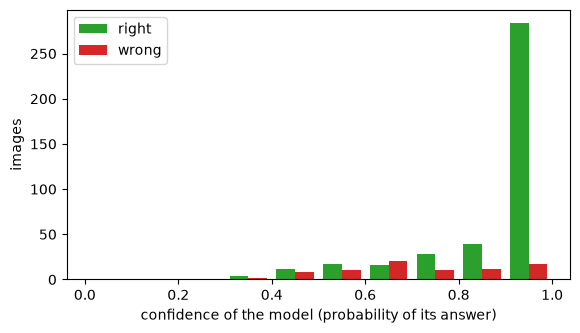

,top-1 (%),top-2 (%)
label,,
cityscape,76.0,94.8
landscape,87.5,94.8
portrait,79.2,94.8
religious_painting,79.2,95.8
still_life,94.8,96.9


In [8]:
top2 = probs.topk(2, dim=1).indices
val["true genre is in the top 2"] = (top2 == y.view(-1, 1)).any(dim=1).numpy()

print(f"mean confidence when right: {val.loc[val['correct'], 'confidence'].mean():.2f} | when wrong: {val.loc[~val['correct'], 'confidence'].mean():.2f}")
print(f"mistakes made with a confidence above 0.8: {(~val['correct'] & (val['confidence'] > 0.8)).sum()} of {(~val['correct']).sum()}")
print(f"top-1 accuracy {val['correct'].mean():.1%} | top-2 accuracy {val['true genre is in the top 2'].mean():.1%}")

plt.figure(figsize=(6.5, 3.5))
plt.hist([val.loc[val["correct"], "confidence"], val.loc[~val["correct"], "confidence"]], bins=10, range=(0, 1),
         label=["right", "wrong"], color=["tab:green", "tab:red"])
plt.xlabel("confidence of the model (probability of its answer)")
plt.ylabel("images")
plt.legend()
plt.show()

val.groupby("label")[["correct", "true genre is in the top 2"]].mean().mul(100).round(1).rename(
    columns={"correct": "top-1 (%)", "true genre is in the top 2": "top-2 (%)"})

## 5. Style and artist: the metadata the model never saw

Genre and style overlap (ADR 0003). Are some styles harder than others, and do the mistakes come from particular styles? Styles with
fewer than 12 validation images are left out (too few to say anything). "Unknown Artist" is the catch-all label.

In [9]:
by_style = val.groupby("style").agg(images=("correct", "size"), error_rate=("correct", lambda s: 100 * (1 - s.mean())))
display(by_style[by_style["images"] >= 12].sort_values("error_rate", ascending=False).round(1))

val["artist known"] = np.where(val["artist"] == "Unknown Artist", "Unknown Artist", "named artist")
val.groupby("artist known").agg(images=("correct", "size"), error_rate=("correct", lambda s: 100 * (1 - s.mean()))).round(1)

,images,error_rate
style,,
Cubism,29,34.5
Symbolism,15,33.3
Art_Nouveau,12,25.0
Early_Renaissance,28,21.4
Expressionism,43,18.6
Rococo,14,14.3
Impressionism,63,14.3
Romanticism,35,14.3
Realism,51,13.7


,images,error_rate
artist known,,
Unknown Artist,319,17.9
named artist,161,14.3


In [10]:
# The styles behind the most frequent mistake.
worst = pairs.iloc[0]
subset = val[(val["label"] == worst["true genre"]) & (val["predicted"] == worst["predicted as"])]
print(f"{worst['true genre']} predicted as {worst['predicted as']}: {len(subset)} images, their styles:")
print(subset["style"].value_counts().to_string())
print(f"\nstyles of ALL the validation images of genre {worst['true genre']}:")
print(val[val["label"] == worst["true genre"]]["style"].value_counts().head(6).to_string())

cityscape predicted as landscape: 18 images, their styles:
style
Impressionism            5
Realism                  4
Post_Impressionism       2
Symbolism                2
Expressionism            2
Naive_Art_Primitivism    1
Rococo                   1
Romanticism              1

styles of ALL the validation images of genre cityscape:
style
Post_Impressionism    24
Impressionism         14
Expressionism         10
Romanticism           10
Realism               10
Cubism                 5


## 6. The most confident mistakes

The 15 images the model got wrong while being most sure of itself. These are the best candidates for **ambiguous labels** (for
example a religious painting that is also a portrait). Only identifiers and metadata are shown here, no image.

In [11]:
mistakes = val[~val["correct"]].sort_values("confidence", ascending=False)
mistakes.head(15)[["id", "label", "predicted", "confidence", "style", "artist"]].round(2)

,id,label,predicted,confidence,style,artist
39,s51_r0348,cityscape,landscape,1.00,Realism,vasily-surikov
203,s42_r0323,portrait,religious_painting,0.99,Realism,james-tissot
60,s51_r0566,cityscape,landscape,0.99,Impressionism,Unknown Artist
56,s51_r0522,cityscape,landscape,0.98,Impressionism,paul-gauguin
197,s42_r0174,portrait,still_life,0.98,Cubism,Unknown Artist
376,s49_r1073,religious_painting,portrait,0.97,Expressionism,Unknown Artist
4,s51_r0053,cityscape,landscape,0.96,Impressionism,paul-gauguin
66,s51_r0606,cityscape,landscape,0.96,Symbolism,Unknown Artist
335,s49_r0584,religious_painting,portrait,0.94,High_Renaissance,Unknown Artist
329,s49_r0485,religious_painting,portrait,0.94,Baroque,Unknown Artist


## 7. Looking at the paintings (off by default)

The best way to understand a mistake is to look at it. **Licence warning:** WikiArt images must never be committed or published. If you
switch `SHOW_EXAMPLES` on, the pictures become part of this notebook's saved output. **Clear the output of the next cell before you
save and commit** (in VS Code: the "..." menu of the cell, then "Clear Cell Outputs"), then set the switch back to `False`.

In [ ]:
SHOW_EXAMPLES = False  # True only to look; then clear this cell's output before saving (licence)

if SHOW_EXAMPLES:
    top = pairs.iloc[0]
    shown = mistakes[(mistakes["label"] == top["true genre"]) & (mistakes["predicted"] == top["predicted as"])].head(8)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax, (_, row) in zip(axes.flat, shown.iterrows()):
        ax.imshow(Image.open(DATA_DIR / row["path"]))
        ax.set_title(f"{row['label']} -> {row['predicted']}\n{row['confidence']:.2f} | {row['style']}", fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    plt.show()
    print("REMEMBER: clear the output of this cell before saving (WikiArt licence), and set SHOW_EXAMPLES back to False.")

## Nothing is saved here

This notebook reads a saved run and the validation images. It writes nothing to `results/` and does not use the test set.

## What we see (final model, validation, 480 images)

| genre | recall | precision | top confusion |
|---|---|---|---|
| still life | **94.8%** | 82.0% | predicted as portrait: 3 of 96 |
| landscape | 87.5% | 79.2% | predicted as cityscape: 6 |
| portrait | 79.2% | 82.6% | predicted as still life: 13, as religious painting: 7 |
| religious painting | 79.2% | 85.4% | predicted as portrait: 13 |
| cityscape | 76.0% | **89.0%** | predicted as landscape: **18** (18.8% of the cityscapes) |

- **The intuition holds, and it is not only religious paintings and portraits.** Across the 10 pairs of genres, the more alike two genres are
  in the network's features, the more they are mixed up (rank correlation 0.86). The two most similar pairs are **cityscape and landscape**
  (similarity 0.88, 24 mistakes both ways) and **portrait and religious painting** (0.87, 20 mistakes both ways), then portrait and still
  life (0.80, 16). So religious paintings and portraits do look alike to the network, but the largest confusion is cityscape against
  landscape. A plausible reason, which we did not check: a city view is often a landscape with buildings.
- **These are mostly not random errors.** The true genre is the model's first or second choice for 95.4% of the images (top-2 accuracy),
  against 83.3% for the first choice alone. The errors are between two plausible genres.
- **But the model is often sure when it is wrong:** confidence 0.90 when right and 0.71 when wrong, and 29 of the 80 mistakes were made with a
  confidence above 0.8. The most confident mistakes are mostly cityscapes called landscapes and religious paintings called portraits: the
  best candidates for ambiguous labels, which no better model could fix.
- **Style:** the hardest are Cubism (34.5% of errors, 29 images), Symbolism (33.3%, 15) and Art Nouveau (25%, 12); the easiest is
  Post-Impressionism (10.6%, 66). These samples are small. The cityscape to landscape mistakes come from many styles (Impressionism 5,
  Realism 4, ...), so it is not a style effect. Named artists 14.3% errors, "Unknown Artist" 17.9%: within the noise.
- Validation only: the test set was not used for this analysis (ADR 0003).